# 03 · AerSimulator ile ilk deneme

**Amaç:** Açısal ölçekleme ve sonlu shot ile Aer üzerinde QNN eğitiminin nasıl yürüdüğünü araştırmak.

**Okuma notu:** Ölçekleyici yalnız eğitim verisine fit edilir. Arşivde eğitim geçmişi oluşmadan grafik çağrısından kaynaklanan NameError vardır. Bu dosya çalışma günlüğüdür; önerilen başlangıç 04 dosyasıdır.

**Durum:** Staj çalışması arşivi. Aşağıdaki çıktılar ZIP içinde kayıtlı geçmiş çalıştırmalara aittir; bu yayına hazırlık sırasında üretilmiş yeni deney sonuçları değildir. Deney kodu ve eski açıklamalar gelişim sürecini göstermek için korunmuştur; yöntem düzeltmeleri ve sınırlılıklar için [çalışma rehberini](../../docs/CALISMA_REHBERI.md), [sonuçları](../../docs/SONUCLAR.md) ve [yöntem incelemesini](../../docs/YONTEM_VE_SINIRLAR.md) okuyun.

**English:** Historical internship experiment. See the [English overview](../../README_EN.md). Saved outputs are historical evidence, not a fresh reproducibility claim.


# Hedef

## Basit bir QNN ile iris veri kümesi üzerinde 2'li sınıflandırma yaparak simülasyonda çalıştırmak.

Simülasyonda çalıştırılmasının birkaç temel nedeni var. IBM, Google gibi firmaların kuantum bilgisayarları gerçek donanımda (hardware) çok kısıtlı, gürültülü (noise) ve sıra beklemeli (queue). Bu nedenle; Kodun çalışması, eğitim süreci ve mantık klasik bilgisayarda kuantum bilgisayarı taklit eden yazılımla test ediliyor. 

Simülasyon aracılığıyla accuracy, loss vs. ideal koşulda görülecek. Sonraki adımda, aynı devreyi gerçek IBM Quantum cihazına gönderdiğinde, sonuçlar gürültü nedeniyle biraz düşer (örneğin %75 → %60 civarı).

Özellikle başlangıç seviyesinde modelin mantığını, parametre güncellemelerini ve accuracy sonuçlarını ideal koşullarda öğrenmek, sonra gerekirse gerçek cihazda çalıştırmak daha iyi.

In [1]:
from sklearn import model_selection, datasets, svm
from sklearn.preprocessing import MinMaxScaler

from qiskit.circuit import ParameterVector
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator

import copy
import numpy as np

**Qiskit'teki hızlı değişimler normal mi?**

❌ Genel yazılım dünyasında normal DEĞİL
✅ Kuantum bilişim alanında NORMAL

**Sebepleri:**

Kuantum bilişim henüz çocukluk döneminde (20 yaşında)

En iyi uygulamalar henüz netleşmedi

Donanım çok hızlı gelişiyor → Yazılım takip etmeli

Araştırma odaklı → Kararlılıktan çok yenilik

**Diğer kütüphanelerle karşılaştırma:**

NumPy: 10+ yıl geriye uyumlu (kararlı alan)

TensorFlow: 2-3 yıl geriye uyumlu (gelişen alan)

Qiskit: 3-6 ay geriye uyumlu (yeni alan)

In [2]:
iris = datasets.load_iris()  # Iris veri kümesini yükledik

X = iris.data[0:100]
Y = iris.target[0:100]

# iris veri kümesinde 150 gözlem, 3 farklı sınıf (setosa, versicolor, virginica) var.
# İlk 100 gözlem alınıyor. Yani sadece ilk iki sınıf (setosa = 0, versicolor = 1).
#Böylece problem binary classification haline getiriliyor.

X_train, X_test, Y_train, Y_test = model_selection.train_test_split(
    X, Y, test_size=0.33, random_state=42
)


- **X (features / bağımsız değişkenler):**
    
    Modelin girdi olarak aldığı veriler → mesela iris çiçeğinin 4 ölçümü.
    
- **Y (labels / bağımlı değişken):**
    
    Modelin tahmin etmeye çalıştığı hedef → mesela çiçek türü (0 veya 1).
    

**train_test_split(X, Y, ...) :**

X_train → eğitimde kullanılacak girdiler

Y_train → eğitimde kullanılacak etiketler

X_test → testte kullanılacak girdiler

Y_test → testte kullanılacak etiketler

| X (özellikler)        | Y (etiket) |
| --------------------- | ---------- |
| \[5.1, 3.5, 1.4, 0.2] | 0          |
| \[7.0, 3.2, 4.7, 1.4] | 1          |


In [3]:
# Feature scaling: [0, pi] 
scaler = MinMaxScaler(feature_range=(0, np.pi))
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)


### Rotation Encoding

**Qubitleri açılarla döndürmek**

Klasik veriyi kuantum devresine gömme (data encoding / embedding) yöntemlerinden biri:

Elinde sayısal değerler var (ör. [5.2, 3.4, 1.4, 0.2]).
Bunları doğrudan kuantum bilgisayar anlayamaz, çünkü qubitler sadece kuantum durumlarını (|0⟩, |1⟩ ve bunların süperpozisyonları) taşıyabilir.

Bu yüzden sayıları, qubitlerin açısal dönüşleri haline getiriyoruz.

**Mesela**
qc.rx(5.2, 0) → q0 qubitini X ekseni etrafında 5.2 radyan döndür.
Böylece “5.2” sayısı → q0’ın kuantum durumuna encode edilmiş olur.
Bu şekilde döndürülerek her bir qubitin bir bilgi sağlaması sağlanılıyor


Rx, Ry, Rz Rotation Gate'lerdir.
Yani qubit’i Bloch küresi üzerinde belirli bir eksen etrafında döndürür.

Qubit'i bir küre üzerindeki bir vektör gibi düşünebilirsin. Rotation gate, bu vektörü döndürür.

**Formül olarak:**
- Rx(θ) → X ekseni etrafında θ kadar döndürür
- Ry(θ) → Y ekseni etrafında θ kadar döndürür
- Rz(θ) → Z ekseni etrafında θ kadar döndürür


* RX(θ) kapısı Bloch küresi üzerinde X ekseni etrafında dönüş yapar.
* [0, π] → Qubit’i Bloch küresinde sadece yarım tur (üstten alta) döndürür. Bu daha sınırlı ama kompakt bir temsil sağlar.

* [0, 2π] → Tam küreyi (üst + alt tarafı) kullanır, yani veriyi daha geniş bir bölgeye yayar.

İkisinin seçimi uygulamaya göre yapılır. Genelde literatürde π veya 2π tercih edilir, çünkü bunlar RX kapısının tüm “farklı” sonuçlarını kapsar.

**Veriyi [0, π] veya [0, 2π] aralığına ölçeklemek:**

π ≈ 3.1416 rad → yani 180°

2π ≈ 6.2832 rad → yani 360°

* Veriyi [0, π] aralığına ölçeklersen → qubit’i 0° ile 180° arasında döndürmüş oluyorsun.

* Veriyi [0, 2π] aralığına ölçeklersen → qubit’i 0° ile 360° arasında döndürmüş oluyorsun.

* RX kapısının periyodik doğasından dolayı gereksiz tekrarları önler.
* Tüm verilerin tutarlı bir açı aralığında temsil edilmesini sağlar.
* QML modelinin daha iyi öğrenmesine yardımcı olur.

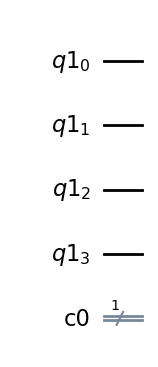

In [4]:
N = 4  # Özellik sayısı (her özellik için bir qubit kullanacağız)
q = QuantumRegister(N)       # N qubitlik kuantum register (girdi)
c = ClassicalRegister(1)     # 1 bitlik klasik register (çıktı), ölçüm sonucunu kaydetmek için
qc = QuantumCircuit(q, c)    # Kuantum devresini oluştur

qc.draw("mpl")  # Devreyi görselleştir

**QuantumRegister:** Qubitleri içerir, yani kuantum bilgisayarın asıl işlem yapan birimleri.

**ClassicalRegister:** Ölçüm sonuçlarının tutulduğu klasik bitler.

**QuantumCircuit:** Kuantum Devresi. Qubitler üzerinde kapılar/operasyonlar uygulanır, sonunda ölçüm yapılıp sonuçlar ClassicalRegister’a aktarılır.

Yani devre, **QuantumRegister** üstünde çalışır ve çıktılarını **ClassicalRegister**’a kaydeder.

Bu basit bir devre

**4 qubit** → giriş özelliklerini encode edeceğin yer.

**1 klasik bit** → ölçüm sonucunu tutacağın yer (modelin tahmini).

In [5]:

def feature_map(X):

    q = QuantumRegister(N)
    c = ClassicalRegister(1)
    qc = QuantumCircuit(q, c)

    for i, x in enumerate(X):
        qc.rx(x, i)
    return qc, c

# Bu fonksiyonla feature_map(X) fonksiyonu = girdi vektörünü al, 
# N qubit’e rotation kapılarıyla encode et, devreyi döndür.

# Qislitin hazır feature map sınıfları var, (örn. ZZFeatureMap, PauliFeatureMap).
# Onlar da aynı mantığı içeride döngüyle yapıyor, ama daha gelişmiş versiyonlar.

Kuantum Devresini oluşturduk, ve bu devreyi ölçmemiz gerekiyor çünkü bir çıktı elde etmeliyiz.

Devreyi çalıştırıp sadece qubitleri döndürmek yetmez. En sonunda ölçüm (measurement) yaparak qubit’in kuantum durumunu klasik bir sayıya (0 veya 1) dönüştürmemiz gerekir.

Bu ölçüm(çıktı) bizim quantum devremizin tahmini olacak. 

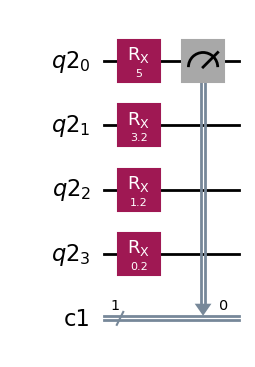

In [6]:
qc, c = feature_map(X_train[5])   # 6. gözlemi feature_map fonksiyonuyla ile devreye encode et
qc.measure(0, c)  # q0 qubitini ölç ve sonucu c’ye (classical register) yaz
qc.draw("mpl")

#### **qc.measure(0, c)**

q0 qubitini ölç ve Ölçüm sonucucunu c (classical register) içine yaz.
Sonuç ya 0 ya da 1 olur.


#### **Neden 4’ünü birden ölçmüyoruz?**

Ölçmek, kuantum bilgisayarda “klasik bilgiye çevirme” demek.

Eğer tüm qubitleri ölçersen, her birinden bir bit alırsın toplamda 4 bitlik çıktı. Ama problemimiz binary (2 sınıf), yani tek bitlik çıktı yeterli.

Fazladan ölçmek, ekstra bilgi getirmez, devreyi daha karmaşık hale getirir.


4 qubit var ama sadece q0 ölçülüyor. O zaman diğer 3 qubit boşa mı gitti?Sadece tek qubit çıkış verdiğine göre, tek özelliğe bakıyormuşuz gibi hissettiriyor. Ama tam olarak öyle sayılmaz çünkü,

1. **Entanglement (dolanıklık):** Variational circuit’te qubitler birbirine bağlanıyor (CNOT, CZ gibi kapılar).Böylece q0’ın son durumu sadece kendi başlangıç değerine değil, diğer 3 qubit’in encode edilmiş özelliklerine de bağlı oluyor. Yani ölçtüğün q0, aslında bütün feature’ların birleşmiş etkisini içeriyor.

2. **Parametreli dönüşümler:** Eğitim sırasında devredeki kapıların açıları öğreniliyor. Bu parametreler sayesinde q0’ın çıktısı “hangi feature kombinasyonuna göre 0/1 demeliyim?” sorusunun cevabını öğreniyor.


Evet, ölçüm sadece 1 qubit’te yapılıyor. Ama o qubit’in durumu, diğer tüm qubitlerden gelen bilgiyle şekillenmiş durumda. Dolayısıyla aslında model tek özelliğe bakmıyor, tüm özellikleri işleyip sonucunu tek bir qubit’te yoğunlaştırıyor.


In [7]:
# Öğrenebilen bir devre oluşturalım şimdi

def variational_circuit(qc, theta):
    for i in range(N-1):
        qc.cx(i, i+1)     # 0→1, 1→2, 2→3... şeklinde bağla
    qc.cx(N-1, 0)     # Son qubit'i ilk qubit'e bağla (halka yap)

    for i in range(N):
        qc.ry(theta[i], i)   # Her qubit'e theta[i] kadar döndür, öğrenilebilir Ry(θ)
    return qc


### Theta = Öğrenilebilir parametreler:

Klasik makine öğrenmesinde nasıl ağırlıklar (weights) varsa, kuantum makine öğrenmesinde de theta parametreleri var.

### Variational circuit nedir?

Eğitilebilir parametreler (θ) içeren kapı katmanlarıdır: genelde Rx/Ry/Rz(θ) döndürmeleri + entanglement (CNOT/CZ).

Eğitim sırasında bir optimizasyon (SGD, COBYLA, SPSA vb.) bu θ açılarını öğrenir; amaç ölçümden hesaplanan loss’u düşürmektir.


### CNOT Zincirleri (Quantum Bağlantılar)

Qubit'ler birbirlerine bağlanıyor (entangled oluyor). Bu bir halka şeklinde oluyor: 0-1-2-3-0 gibi, Bu önemli çünkü quantum'da qubit'ler birbirini etkileyebiliyor!

- CNOT'lar: Qubit'leri zincirleme bağlar (arkadaşların birbirini etkiler)
- RY(theta): Her qubit'i ayarlanabilir açıda döndürür (öğrenilebilir düğmeler)
- Halka yapısı: İlk ve son qubit'i bağlar (döngü tamamlanır)

Bu theta değerleri makine öğrenmesiyle otomatik optimize edilir. Devre gittikçe daha iyi tahminler yapar, Quantum bilgisayarın süpergücünü makine öğrenmesiyle birleştirir!


- CNOT ring: Minimal bağlantıyla küresel etkileşim sağlar; q0 ↔ … ↔ qN-1 hepsi bağlıdır. 

Artık Qiskit’te doğrudan cnot isimli bir metod yok. Yeni versiyonlarda bunun karşılığı qc.cx(...) oldu. Eski kodlara denk gelirsen diye. 

- Sadece Ry katmanı: Basit ama etkili; öğrenilebilirlik sağlar. İhtiyaç olursa Ry+Rz veya tekrar entanglement eklenerek ifade gücü artırılır (daha karmaşık karar sınırları).

**qc.barrier()**

Qiskit’te devreyi yazdıktan sonra transpiler (derleyici) devreyi optimize eder. Kapıların sırasını değiştirebilir, Gereksiz kapıları silebilir, Daha kısa daha hızlı bir devreye dönüştürür.

Bu çok faydalı ama bazen biz devrenin belli kısımlarını ayrı ayrı görmek veya kapıların sırayla uygulanmasını garanti etmek isteriz.

Barrier, derleyicinin (transpiler) kapıları yer değiştirmesini engelleyen “çit” gibidir; görsel olarak blokları ayırır ve feature map ile variational katmanı iki ayrı bölüm gibi görmeyi sağlar.

qc.barrier() koyduğunda: Transpiler o noktada kapıları karıştırmaz veya yer değiştirmez. Yani, “buradan öncesi → Feature Map, buradan sonrası → Variational Circuit” şeklinde çizgisel bir ayırıcı olur.


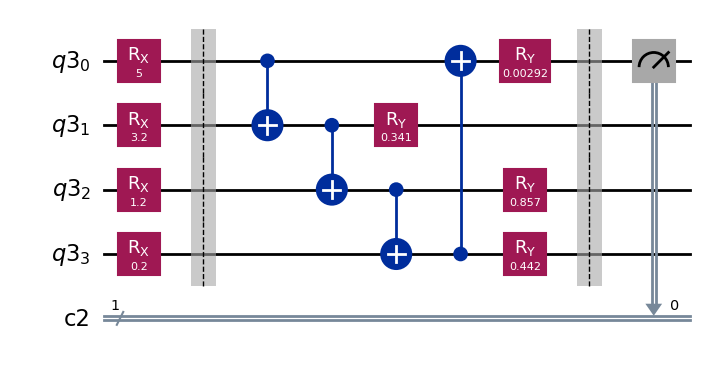

In [8]:

qc, c =feature_map(X_train[5])

qc.barrier()

qc = variational_circuit(qc, np.random.rand(N))

qc.barrier()

# measurement operator
qc.measure(0,c)

# Devreyi çizelim
qc.draw("mpl")



In [9]:
theta = np.random.rand(N) * np.pi

qc, c = feature_map(X_train_s[5])  # <<<<< burada 2 değişken
qc.barrier()
qc = variational_circuit(qc, theta)
qc.barrier()
qc.measure(0, c[0])  # q0 -> c0


In [11]:
# AerSimulator ile çalıştır
from qiskit import transpile
backend = AerSimulator()
tqc = transpile(qc, backend)
shots = 2048
res = backend.run(tqc, shots=shots, seed_simulator=42).result()
counts = res.get_counts(tqc)

nshots = sum(counts.values())
p1 = counts.get('1', 0) / nshots
print("counts:", counts)
print("p(1):", p1)

counts: {'0': 1248, '1': 800}
p(1): 0.390625


In [12]:
print(Y_train[5])

0


In [13]:
def quantum_nn(X, theta, shots=2048):
    """
    Quantum Neural Network fonksiyonu

    Parameters
    X : numpy.ndarray
        Girdi özellikleri (ölçeklenmiş feature vektörü).
    theta : numpy.ndarray
        Variational parametreler (öğrenilebilir açılar).
    simulator : bool, optional
        Simülasyon için bayrak. Şu an kullanılmıyor ama ileride
        farklı backend'ler (ör. gerçek IBM QPU) seçimi için
        kullanılabilir. Varsayılan True.

    Returns
    float
        '1' durumunun olasılığı (0 ile 1 arasında).
    """
    # Feature map
    qc, c = feature_map(X)

    # Variational circuit
    qc = variational_circuit(qc, theta)

    #  Ölçüm
    qc.measure(0, c[0])   # sadece q0 ölçülüyor (binary)

    # AerSimulator
    backend = AerSimulator()
    tqc = transpile(qc, backend)

    # Çalıştır
    job = backend.run(tqc, shots=shots, seed_simulator=42)
    result = job.result()
    counts = result.get_counts(tqc)

    # Olasılık p(1)
    p1 = counts.get('1', 0) / shots
    return p1


In [14]:
prediction = quantum_nn(X_train[5], np.random.rand(N))
prediction

0.67822265625

In [15]:
target = Y_train[5]
target

np.int64(0)

In [16]:
def loss(prediction, target):
    """Mean Squared Error loss"""
    return (target - prediction)**2

### Stochastic Gradient Descent (SGD): 

Amaç kayıp fonksiyonunu (loss) 𝐿(𝜃) küçültmek.

Bunun için parametre vektörünü (𝜃: devredeki RY açıları) adım adım güncelliyoruz.

Her tek eğitim örneği için ileri geçiş (prediction) yap, kaybı hesapla, hemen güncelle. (Yani örnek başına güncelleme.)

* Mini-batch: 16–64 gibi küçük gruplarla aynı işlemi yap.
* Full-batch: Tüm eğitim setinin ortalamasını alıp epoch başına bir kez güncelle.

* Döngü: örnek → prediction → loss → gradient → θ güncelle. olarak ilerliyor

Eta (η): güncelleme adımı; hiperparametredir, model öğrenmez—sen seçersin.

In [17]:
# FINITE DIFFERENCE GRADIENT yani sonlu fark gradyanı

def gradient(X, Y, theta):
    """
    Finite difference ile gradient hesaplama
    """
    delta = 0.01  # Küçük step size
    grad = []
    
    for i in range(len(theta)):
        # theta[i]'yi delta kadar artır
        dtheta = copy.copy(theta)
        dtheta[i] += delta
        
        # İki prediction hesapla
        pred1 = quantum_nn(X, dtheta)     # theta[i] + delta ile
        pred2 = quantum_nn(X, theta)      # original theta ile
        
        # Finite difference: (f(x+h) - f(x)) / h
        gradient_i = (loss(pred1, Y) - loss(pred2, Y)) / delta
        grad.append(gradient_i)
    
    return np.array(grad)

In [18]:
# ACCURACY Fonksiyonu

def accuracy(X, Y, theta):
    """
    Classification accuracy hesaplama
   
    X: örnekler (özellik vektörleri)
    Y: gerçek etiketler (0 veya 1)
    theta: devredeki öğrenilebilir parametreler

    Her örnek (X_i) için quantum_nn(X_i, theta) çağrılır 
    p(1) olasılığı döner.
    Eşik 0.5 ile sınıf tahmini yapılır: p < 0.5 → 0, p ≥ 0.5 → 1.
    Tahmin, gerçek etiket Y_i ile uyuşursa sayaç (counter) artırılır.

    Çıktı: counter / len(Y) → doğru tahmin oranı (0–1 arasında).

    Not: Döngü her örnek için devreyi çalıştırdığı için yavaştır.
    ama mantık olarak doğru bir accuracy hesaplamasıdır.
    
    """
    counter = 0
    
    for X_i, Y_i in zip(X, Y):
        prediction = quantum_nn(X_i, theta)
        
        # Binary classification: 0.5 threshold
        if prediction < 0.5 and Y_i == 0:
            counter += 1
        elif prediction >= 0.5 and Y_i == 1:
            counter += 1
    
    return counter / len(Y)


## train_simple_qnn(...)

### Amaç:
  QNN’in parametrelerini (theta) SGD mantığıyla eğitmek ve her epoch sonunda
  loss / train accuracy / test accuracy değerlerini raporlamak.

### Girdiler:
  X_train, Y_train, X_test, Y_test : veri ve etiketler (binary 0/1)
  epochs : kaç kez tüm eğitim verisi üzerinden geçileceği
  eta    : öğrenme oranı (learning rate, hiperparametre)

### Adımlar:
1) Başlatma:
   - theta = np.ones(N): Parametreleri 1’lerle başlatır (tutorial uyumlu).
   - history listeleri: loss, train_acc, test_acc kaydı için boş listeler.

2) Epoch döngüsü (epochs kez):
   - loss_tmp = []: Bu epoch’taki örnek-başı loss’ları toplayacağız.
   - Eğitim örnekleri üzerinde tek tek dolaş:
       a) prediction = quantum_nn(X_i, theta)   # ileri geçiş, p(|1⟩)
       b) current_loss = loss(prediction, Y_i)  # (p − y)^2
          -> loss_tmp.append(current_loss)
       c) grad = gradient(X_i, Y_i, theta)      # finite difference ile ∂L/∂theta
       d) theta = theta − eta * grad            # gradient descent güncellemesi
     (Bu kısım örnek-bazlı güncelleme olduğu için “stochastic” karakterdedir.)

   - Epoch sonunda:
       avg_loss = mean(loss_tmp)                # o epoch’un ortalama MSE’si
       train_acc = accuracy(X_train, Y_train, theta)  # 0.5 eşik ile doğruluk
       test_acc  = accuracy(X_test,  Y_test,  theta)

   - Kayıt ve çıktı:
       loss_list.append(avg_loss), train_acc_list.append(train_acc), test_acc_list.append(test_acc)
       print(...) ile tablo satırı (epoch, loss, train/test acc) yazdırılır.

3) Dönüş:
   return theta, loss_list, train_acc_list, test_acc_list
   -> En son öğrenilmiş parametreler ve eğitim seyri (plot için) döner.

### Notlar:
- quantum_nn her çağrıda devreyi çalıştırdığı için eğitim yavaştır.
- gradient finite-difference ile hesaplandığından her parametre için ekstra ileri geçiş gerekir.
- eta çok büyükse dalgalanır, çok küçükse yavaş öğrenir (hiperparametre ayarı önemlidir).
"""


In [19]:
# Hem training yapan hem de test accuracy hesaplayan fonksiyon

def train_simple_qnn(X_train, Y_train, X_test, Y_test, epochs=10, eta=0.05):
    """
    Basit QNN training
    """
    # Başlangıç parametreleri
    theta = np.ones(N)  # Tutorial gibi ones ile başla
    
    # Training history
    loss_list = []
    train_acc_list = []
    test_acc_list = []
    
    print("Epoch \t Loss \t Training Acc \t Test Acc")
    print("-" * 50)
    
    for epoch in range(epochs):
        loss_tmp = []
        
        # Her training sample için
        for X_i, Y_i in zip(X_train, Y_train):
            # Forward pass
            prediction = quantum_nn(X_i, theta)
            
            # Loss hesapla
            current_loss = loss(prediction, Y_i)
            loss_tmp.append(current_loss)
            
            # Gradient hesapla ve theta güncelle
            grad = gradient(X_i, Y_i, theta)
            theta = theta - eta * grad  # Gradient descent rule
        
        # Epoch istatistikleri
        avg_loss = np.mean(loss_tmp)
        train_acc = accuracy(X_train, Y_train, theta)
        test_acc = accuracy(X_test, Y_test, theta)
        
        # Kaydet
        loss_list.append(avg_loss)
        train_acc_list.append(train_acc)
        test_acc_list.append(test_acc)
        
        # Progress yazdır
        print(f"{epoch:5d} \t {avg_loss:.3f} \t {train_acc:11.3f} \t {test_acc:8.3f}")
    
    return theta, loss_list, train_acc_list, test_acc_list


In [20]:
#  Görselleştirme Fonksiyonu
import matplotlib.pyplot as plt 

def plot_training_simple(loss_list, train_acc_list, test_acc_list):
    """
    Training sonuçlarını görselleştir
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    # Loss plot
    ax1.plot(loss_list, 'b-', linewidth=2, label='Training Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss (MSE)')
    ax1.set_title('Training Loss Over Time')
    ax1.grid(True, alpha=0.3)
    ax1.legend()
    
    # Accuracy plot
    ax2.plot(train_acc_list, 'g-', linewidth=2, label='Training Accuracy')
    ax2.plot(test_acc_list, 'r-', linewidth=2, label='Test Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.set_title('Accuracy Over Time')
    ax2.grid(True, alpha=0.3)
    ax2.legend()
    ax2.set_ylim([0, 1])
    
    plt.tight_layout()
    plt.show()

In [21]:
plot_training_simple(losses, train_accs, test_accs)


NameError: name 'losses' is not defined

Simple QNN Training (Tutorial Method)
Epoch 	 Loss 	 Training Acc 	 Test Acc
--------------------------------------------------
    0 	 0.279 	       0.119 	    0.152
    1 	 0.261 	       0.358 	    0.364
    2 	 0.245 	       0.866 	    0.727
    3 	 0.231 	       0.881 	    0.758
    4 	 0.227 	       0.881 	    0.818
    5 	 0.220 	       0.881 	    0.818
    6 	 0.216 	       0.866 	    0.818
    7 	 0.213 	       0.866 	    0.788
    8 	 0.208 	       0.866 	    0.848
    9 	 0.206 	       0.881 	    0.848

 Training Completed!
Final Training Accuracy: 0.881
Final Test Accuracy: 0.848
Final Loss: 0.206


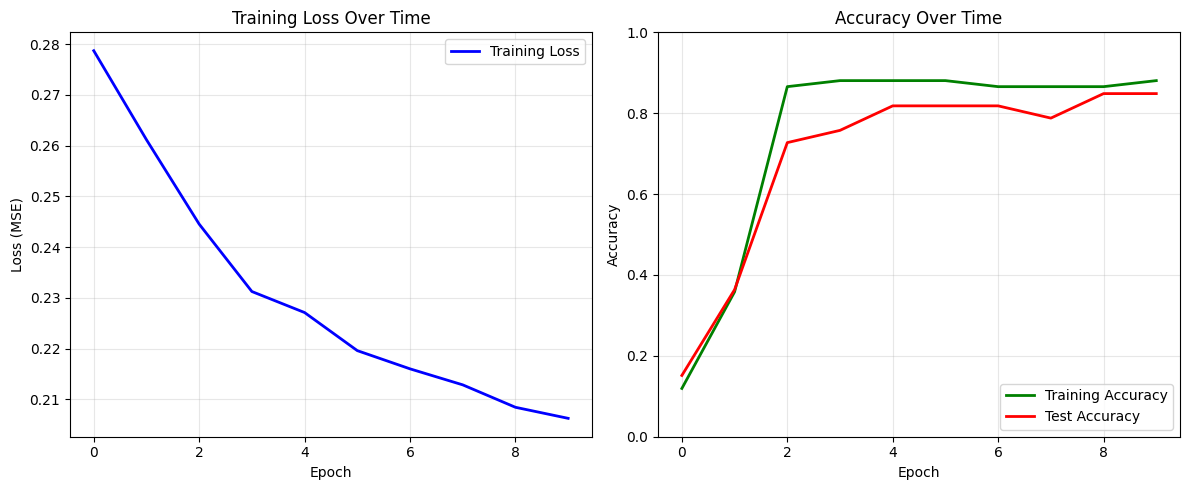


 Sample Test Predictions:
Sample 1: Pred=0.502 → Class=1, Actual=1
Sample 2: Pred=0.548 → Class=1, Actual=1
Sample 3: Pred=0.514 → Class=1, Actual=1
Sample 4: Pred=0.442 → Class=0, Actual=0
Sample 5: Pred=0.604 → Class=1, Actual=0


In [22]:
# 6. ÇALIŞTIRILACAK KOD


if __name__ == "__main__":
    print("Simple QNN Training (Tutorial Method)")
    print("=" * 60)
    
    # Hyperparameters
    N = 4  # Feature count
    eta = 0.05  # Learning rate
    epochs = 10
    
    # Training başlat
    optimal_theta, losses, train_accs, test_accs = train_simple_qnn(
        X_train, Y_train, X_test, Y_test, 
        epochs=epochs, eta=eta
    )
    
    print(f"\n Training Completed!")
    print(f"Final Training Accuracy: {train_accs[-1]:.3f}")
    print(f"Final Test Accuracy: {test_accs[-1]:.3f}")
    print(f"Final Loss: {losses[-1]:.3f}")
    
    # Sonuçları görselleştir
    plot_training_simple(losses, train_accs, test_accs)
    
    # Final predictions
    print(f"\n Sample Test Predictions:")
    for i in range(5):
        pred = quantum_nn(X_test[i], optimal_theta)
        actual = Y_test[i]
        predicted_class = 1 if pred >= 0.5 else 0
        print(f"Sample {i+1}: Pred={pred:.3f} → Class={predicted_class}, Actual={actual}")